Phase 4: Train/Test Split
Since this is time series data, we never shuffle. We take the first 80% chronologically as train and the last 20% as test. To prevent target leakage (our target uses 5-day forward returns), we insert a 5-day gap between train and test.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 5)

df = pd.read_csv('../data/processed/nsei_features.csv', parse_dates=['Date'], index_col='Date')
print(f"Loaded: {df.shape}")
print(f"Date range: {df.index.min().date()} → {df.index.max().date()}")

Loaded: (1612, 36)
Date range: 2020-03-13 → 2026-09-23


4.1 Define Features and Target
We exclude Target_Volatility (the target), Regime (categorical, derived from target-leaking rolling vol), and raw OHLCV columns that would leak future info if unshifted.

In [2]:
TARGET = 'Target_Volatility'

# Columns to exclude from features
# 'Regime' is derived from rolling vol, and OHLCV raw values are not stationary
EXCLUDE = [
    TARGET,
    'Regime',
    'Open', 'High', 'Low', 'Close', 'Volume',   # raw levels (non-stationary)
    'High_Low_Range', 'Volume_Change',
    'MA_5', 'MA_20', 'MA_50',                    # raw MA levels (non-stationary)
    'Volume_MA_5', 'Volume_MA_20',
    'MACD', 'MACD_signal',                       # MACD levels depend on price scale
]

FEATURES = [c for c in df.columns if c not in EXCLUDE]
print(f"Number of features: {len(FEATURES)}")
for f in FEATURES:
    print(f" - {f}")

Number of features: 20
 - Return
 - Return_lag1
 - Return_lag2
 - Return_lag3
 - Return_lag5
 - Return_lag10
 - AbsReturn_lag1
 - AbsReturn_lag2
 - AbsReturn_lag3
 - AbsReturn_lag5
 - Vol_rolling_5
 - Vol_rolling_10
 - Vol_rolling_20
 - AbsReturn_roll_5
 - Close_MA20_ratio
 - Close_MA50_ratio
 - RSI_14
 - MACD_hist
 - ATR_14
 - Volume_ratio


4.2 Time-Based Split (80/20) with a Gap
We split chronologically. We also remove the last gap_size rows from the train set so their targets don't overlap with the test window.

In [3]:
FORWARD_WINDOW = 5   # matches the target definition
TRAIN_RATIO = 0.80

n = len(df)
train_end = int(n * TRAIN_RATIO)

# Apply gap: drop last FORWARD_WINDOW rows from train
train_df = df.iloc[:train_end - FORWARD_WINDOW].copy()
test_df  = df.iloc[train_end:].copy()

X_train = train_df[FEATURES]
y_train = train_df[TARGET]
X_test  = test_df[FEATURES]
y_test  = test_df[TARGET]

print(f"Train period: {X_train.index.min().date()} → {X_train.index.max().date()}  (n={len(X_train)})")
print(f"Test  period: {X_test.index.min().date()} → {X_test.index.max().date()}  (n={len(X_test)})")

# Sanity: no overlap
assert X_train.index.max() < X_test.index.min(), "Train/test overlap detected!"
gap_days = (X_test.index.min() - X_train.index.max()).days
print(f"\nGap between train end and test start: {gap_days} calendar days (~{FORWARD_WINDOW} trading days) ✓")

Train period: 2020-03-13 → 2025-05-28  (n=1284)
Test  period: 2025-06-05 → 2026-09-23  (n=323)

Gap between train end and test start: 8 calendar days (~5 trading days) ✓


4.3 Visualize the Split
Plot the target over time, coloring train vs test regions.

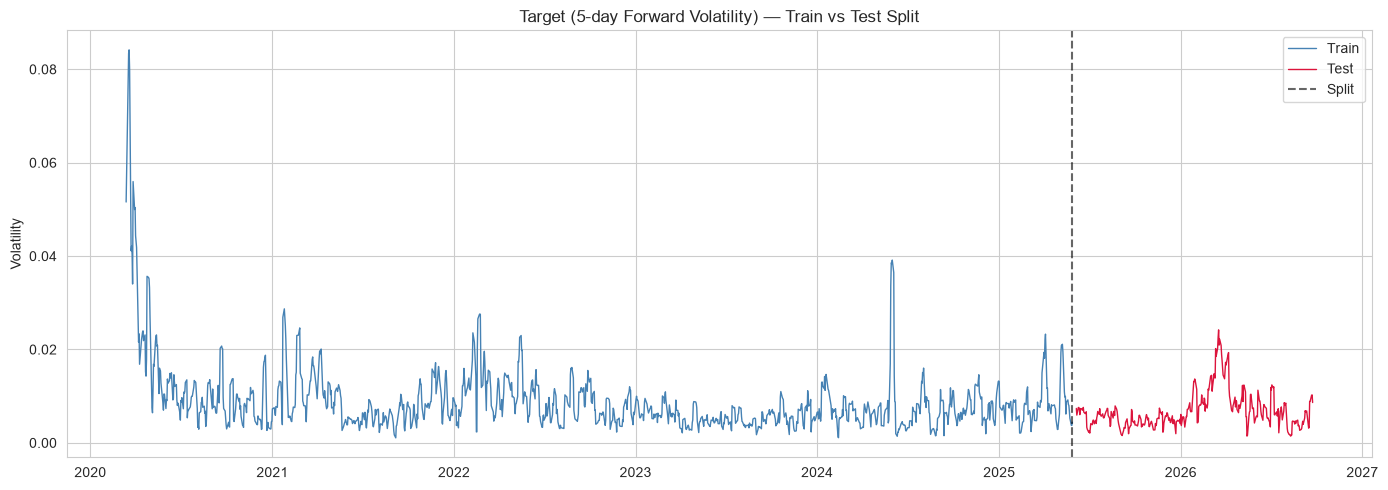

In [4]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train_df.index, train_df[TARGET], label='Train', color='steelblue', linewidth=1)
ax.plot(test_df.index, test_df[TARGET], label='Test', color='crimson', linewidth=1)
ax.axvline(X_train.index.max(), color='black', linestyle='--', alpha=0.6, label='Split')
ax.set_title('Target (5-day Forward Volatility) — Train vs Test Split')
ax.set_ylabel('Volatility'); ax.legend()
plt.tight_layout()
plt.savefig('../reports/figures/09_train_test_split.png', dpi=120)
plt.show()

4.4 Feature Scale Comparison
Verify train and test distributions aren't wildly different (a common failure mode).

In [5]:
compare = pd.DataFrame({
    'train_mean': X_train.mean(),
    'test_mean':  X_test.mean(),
    'train_std':  X_train.std(),
    'test_std':   X_test.std(),
})
compare['mean_shift_%'] = ((compare['test_mean'] - compare['train_mean']) /
                           compare['train_mean'].replace(0, np.nan) * 100).round(1)
display(compare.round(4))

,train_mean,test_mean,train_std,test_std,mean_shift_%
Return,0.0007,-0.0002,0.0117,0.0077,-120.6
Return_lag1,0.0007,-0.0002,0.0120,0.0077,-123.5
Return_lag2,0.0007,-0.0002,0.0120,0.0077,-124.9
Return_lag3,0.0006,-0.0002,0.0120,0.0077,-128.8
Return_lag5,0.0006,-0.0002,0.0121,0.0077,-132.4
Return_lag10,0.0006,-0.0002,0.0121,0.0077,-126.3
AbsReturn_lag1,0.0077,0.0057,0.0091,0.0052,-26.1
AbsReturn_lag2,0.0077,0.0057,0.0091,0.0052,-25.9
AbsReturn_lag3,0.0078,0.0057,0.0092,0.0052,-26.2
AbsReturn_lag5,0.0078,0.0057,0.0092,0.0052,-26.3


4.5 Walk-Forward Validation (Set Up)
Instead of a single train/test split, walk-forward CV gives a more robust estimate of performance. We'll use TimeSeriesSplit from sklearn — expanding window with 5 folds.

In [14]:

import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)


Python executable: c:\Users\User\AppData\Local\Programs\Python\Python312\python.exe
Python version: 3.12.4 (tags/v3.12.4:8e8a4ba, Jun  6 2024, 19:30:16) [MSC v.1940 64 bit (AMD64)]


In [15]:

%pip show scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [16]:

%pip install scikit-learn==1.9.1

  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:

import sklearn
from sklearn.model_selection import TimeSeriesSplit

print("scikit-learn version:", sklearn.__version__)
print("TimeSeriesSplit imported successfully!")

scikit-learn version: 1.9.1
TimeSeriesSplit imported successfully!


In [18]:
# Code - Walk-Forward Setup
from sklearn.model_selection import TimeSeriesSplit

N_SPLITS = 5
tscv = TimeSeriesSplit(n_splits=N_SPLITS, gap=FORWARD_WINDOW)

fold_info = []
for i, (tr_idx, va_idx) in enumerate(tscv.split(X_train)):
    fold_info.append({
        'fold': i + 1,
        'train_start': X_train.index[tr_idx[0]].date(),
        'train_end':   X_train.index[tr_idx[-1]].date(),
        'val_start':   X_train.index[va_idx[0]].date(),
        'val_end':     X_train.index[va_idx[-1]].date(),
        'n_train': len(tr_idx),
        'n_val':   len(va_idx),
    })

display(pd.DataFrame(fold_info))

,fold,train_start,train_end,val_start,val_end,n_train,n_val
0,1,2020-03-13,2021-01-13,2021-01-21,2021-12-03,209,214
1,2,2020-03-13,2021-11-26,2021-12-06,2022-10-13,423,214
2,3,2020-03-13,2022-10-06,2022-10-14,2023-08-24,637,214
3,4,2020-03-13,2023-08-17,2023-08-25,2024-07-15,851,214
4,5,2020-03-13,2024-07-08,2024-07-16,2025-05-28,1065,214


In [19]:
# Code - Save Split Indices
import os
os.makedirs('../data/processed/splits', exist_ok=True)

pd.Series(X_train.index).to_csv('../data/processed/splits/train_dates.csv', index=False, header=['Date'])
pd.Series(X_test.index).to_csv('../data/processed/splits/test_dates.csv', index=False, header=['Date'])

print("Saved train/test date indices.")
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")

Saved train/test date indices.
X_train: (1284, 20), X_test: (323, 20)
y_train: (1284,), y_test: (323,)
